# 🚢 Task 2: Exploratory Data Analysis (EDA) — Titanic Dataset
**AI & ML Internship — Elevate Labs**

**Objective:** Understand data using statistics and visualizations.
**Tools:** Pandas, Matplotlib, Seaborn, Plotly

**Pipeline**
1. Load the data & first look
2. Summary statistics (mean, median, std, skewness...)
3. Histograms & boxplots for numeric features
4. Categorical feature analysis
5. Correlation matrix & pairplot (feature relationships)
6. Patterns, trends & anomalies (interactive Plotly charts)
7. Feature-level inferences
8. Key findings & interview questions

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)        # static plots
os.makedirs("plots_html", exist_ok=True)    # interactive Plotly charts
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

SURV_PALETTE = {0: "#e74c3c", 1: "#2ecc71"}   # red = died, green = survived
print("✅ Libraries imported")

✅ Libraries imported


## 📥 Step 0: Load the Dataset & First Look

In [2]:
# Auto-detect the Titanic CSV (works on Kaggle via "+ Add Input" AND locally from the data/ folder)
csv_path = None
for root_dir in ["/kaggle/input", "data"]:
    for dirname, _, filenames in os.walk(root_dir):
        for f in filenames:
            if not f.lower().endswith(".csv") or "cleaned" in f.lower():
                continue
            p = os.path.join(dirname, f)
            try:
                cols = pd.read_csv(p, nrows=1).columns
            except Exception:
                continue
            if {"Survived", "Pclass", "Sex", "Age"}.issubset(cols):
                if csv_path is None or "test" not in f.lower():
                    csv_path = p

if csv_path is None:
    raise FileNotFoundError("Titanic CSV not found. Add a Titanic dataset on Kaggle or place Titanic-Dataset.csv in data/.")

print("Using file:", csv_path)
df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Using file: data/Titanic-Dataset.csv
Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})
print(missing[missing["Missing Count"] > 0])
print("\nDuplicate rows:", df.duplicated().sum())

          Missing Count  Missing %
Age                 177      19.87
Cabin               687      77.10
Embarked              2       0.22

Duplicate rows: 0


## 📊 Step 1: Summary Statistics
Mean, median, standard deviation, quartiles, skewness and kurtosis for the numeric features,
plus counts / unique values / top category for the categorical ones.

In [5]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]

stats = df[num_cols].describe().T
stats["median"] = df[num_cols].median()
stats["skewness"] = df[num_cols].skew()
stats["kurtosis"] = df[num_cols].kurt()
stats["missing"] = df[num_cols].isnull().sum()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis,missing
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00,28.00,0.39,0.18,177
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33,14.45,4.79,33.40,0
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00,0.00,3.70,17.88,0
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00,0.00,2.75,9.78,0


In [6]:
cat_cols = ["Survived", "Pclass", "Sex", "Embarked"]
for c in cat_cols:
    vc = df[c].value_counts(dropna=False)
    pct = (vc / len(df) * 100).round(1)
    print(f"--- {c} ---")
    print(pd.DataFrame({"count": vc, "%": pct}), "\n")

--- Survived ---
          count     %
Survived             
0           549  61.6
1           342  38.4 

--- Pclass ---
        count     %
Pclass             
3         491  55.1
1         216  24.2
2         184  20.7 

--- Sex ---
        count     %
Sex                
male      577  64.8
female    314  35.2 

--- Embarked ---
          count     %
Embarked             
S           644  72.3
C           168  18.9
Q            77   8.6
NaN           2   0.2 



In [7]:
df.describe(include="object").T

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


### 📝 Observations (summary statistics)
- Overall **survival rate is ~38.4%** (342 of 891 passengers survived)
- **Age**: mean 29.7 vs median 28 → nearly symmetric (skewness ≈ 0.39), 177 values missing
- **Fare**: mean 32.2 vs median 14.45 → strongly **right-skewed** (skewness ≈ 4.79), max 512.33
- **SibSp** and **Parch** are mostly 0 → heavily skewed discrete counts
- ~65% of passengers are male and ~72% boarded at Southampton (S)

## 📈 Step 2: Histograms & Boxplots (Numeric Features)
Histograms show the **shape** of each distribution, boxplots show the **spread and outliers**.

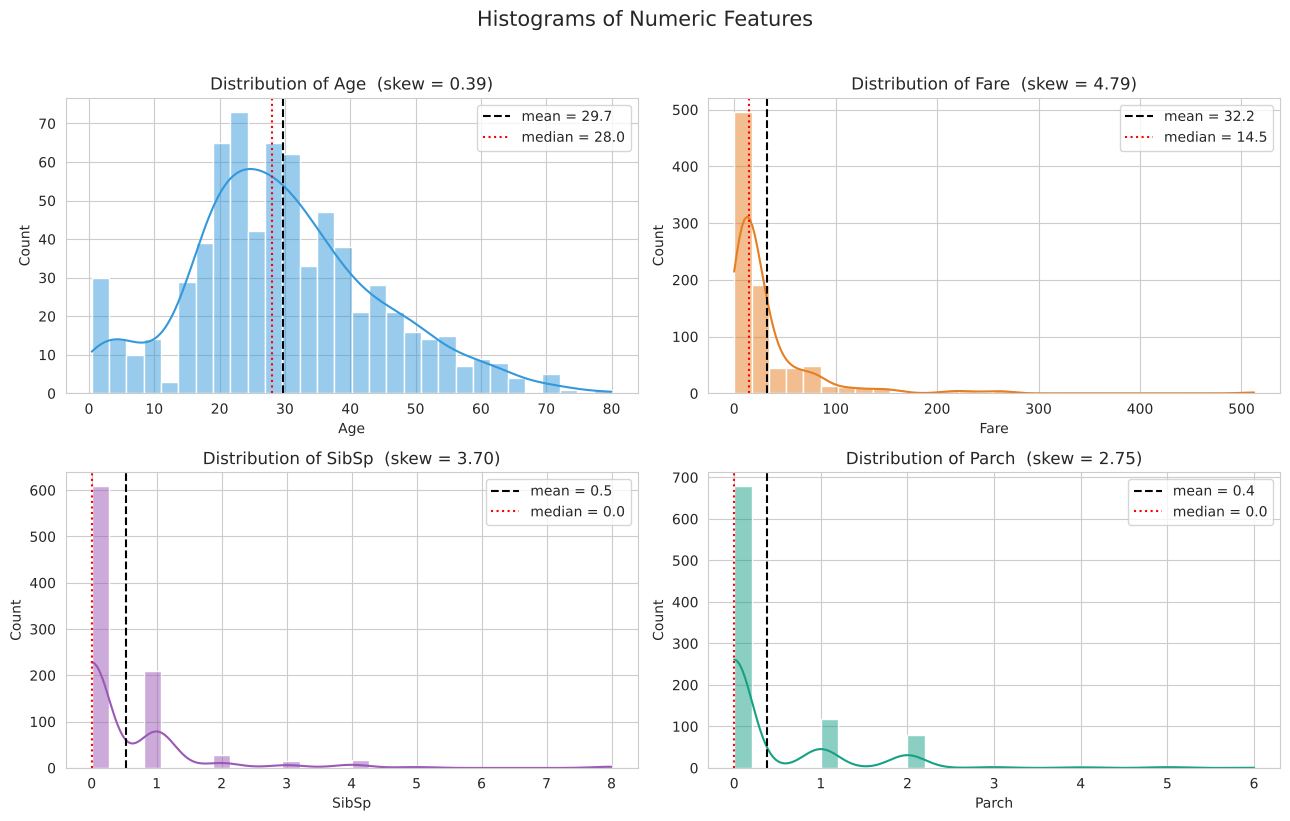

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
colors = ["#3498db", "#e67e22", "#9b59b6", "#16a085"]
for ax, col, color in zip(axes.ravel(), num_cols, colors):
    sns.histplot(df[col].dropna(), kde=True, bins=30, ax=ax, color=color)
    ax.axvline(df[col].mean(), color="black", linestyle="--", label=f"mean = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="red", linestyle=":", label=f"median = {df[col].median():.1f}")
    ax.set_title(f"Distribution of {col}  (skew = {df[col].skew():.2f})")
    ax.legend()
plt.suptitle("Histograms of Numeric Features", y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig("images/01_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

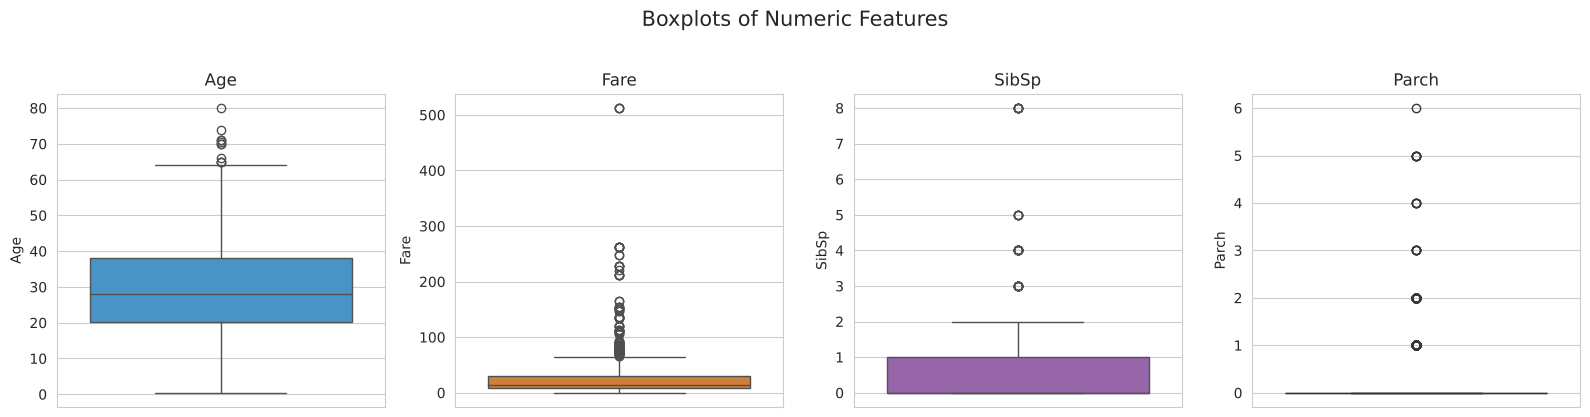

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col, color in zip(axes, num_cols, colors):
    sns.boxplot(y=df[col], ax=ax, color=color)
    ax.set_title(col)
plt.suptitle("Boxplots of Numeric Features", y=1.03, fontsize=15)
plt.tight_layout()
plt.savefig("images/02_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# How many IQR outliers does each numeric feature have?
rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append([c, round(lo, 2), round(hi, 2), int(((s < lo) | (s > hi)).sum())])
pd.DataFrame(rows, columns=["Feature", "Lower bound", "Upper bound", "# Outliers (IQR)"])

,Feature,Lower bound,Upper bound,# Outliers (IQR)
0,Age,-6.69,64.81,11
1,Fare,-26.72,65.63,116
2,SibSp,-1.50,2.50,46
3,Parch,0.00,0.00,213


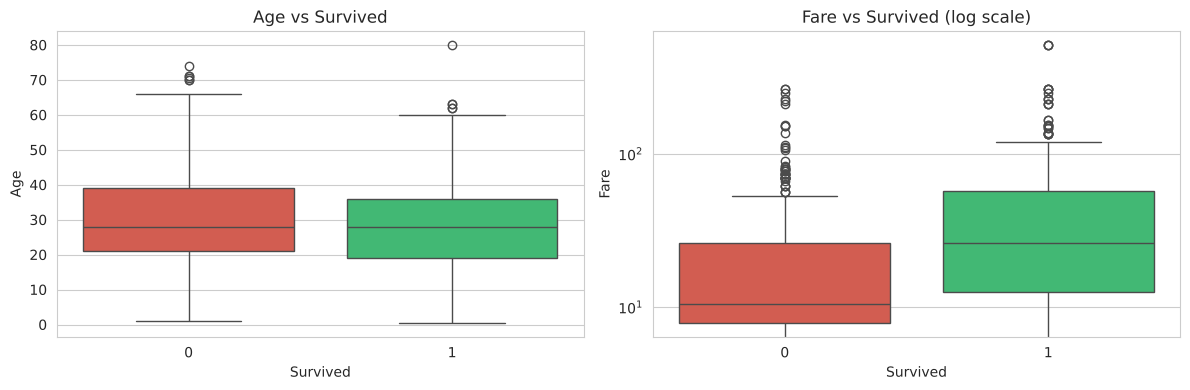

In [11]:
# Boxplots split by survival: do survivors differ?
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Survived", y="Age", palette=["#e74c3c", "#2ecc71"], ax=axes[0])
axes[0].set_title("Age vs Survived")
sns.boxplot(data=df, x="Survived", y="Fare", palette=["#e74c3c", "#2ecc71"], ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Fare vs Survived (log scale)")
plt.tight_layout()
plt.savefig("images/03_boxplots_by_survival.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (distributions)
- **Age** is roughly bell-shaped with a small bump of young children
- **Fare** has a long right tail (116 IQR outliers); it needs a log transform before many ML models
- **Parch** (213) and **SibSp** (46) show many "outliers" only because most passengers travelled alone: these are real values, not errors
- Survivors paid noticeably higher fares than non-survivors; the age spread is similar for both groups

## 🧮 Step 3: Categorical Features
How is each category distributed, and how does it relate to survival?

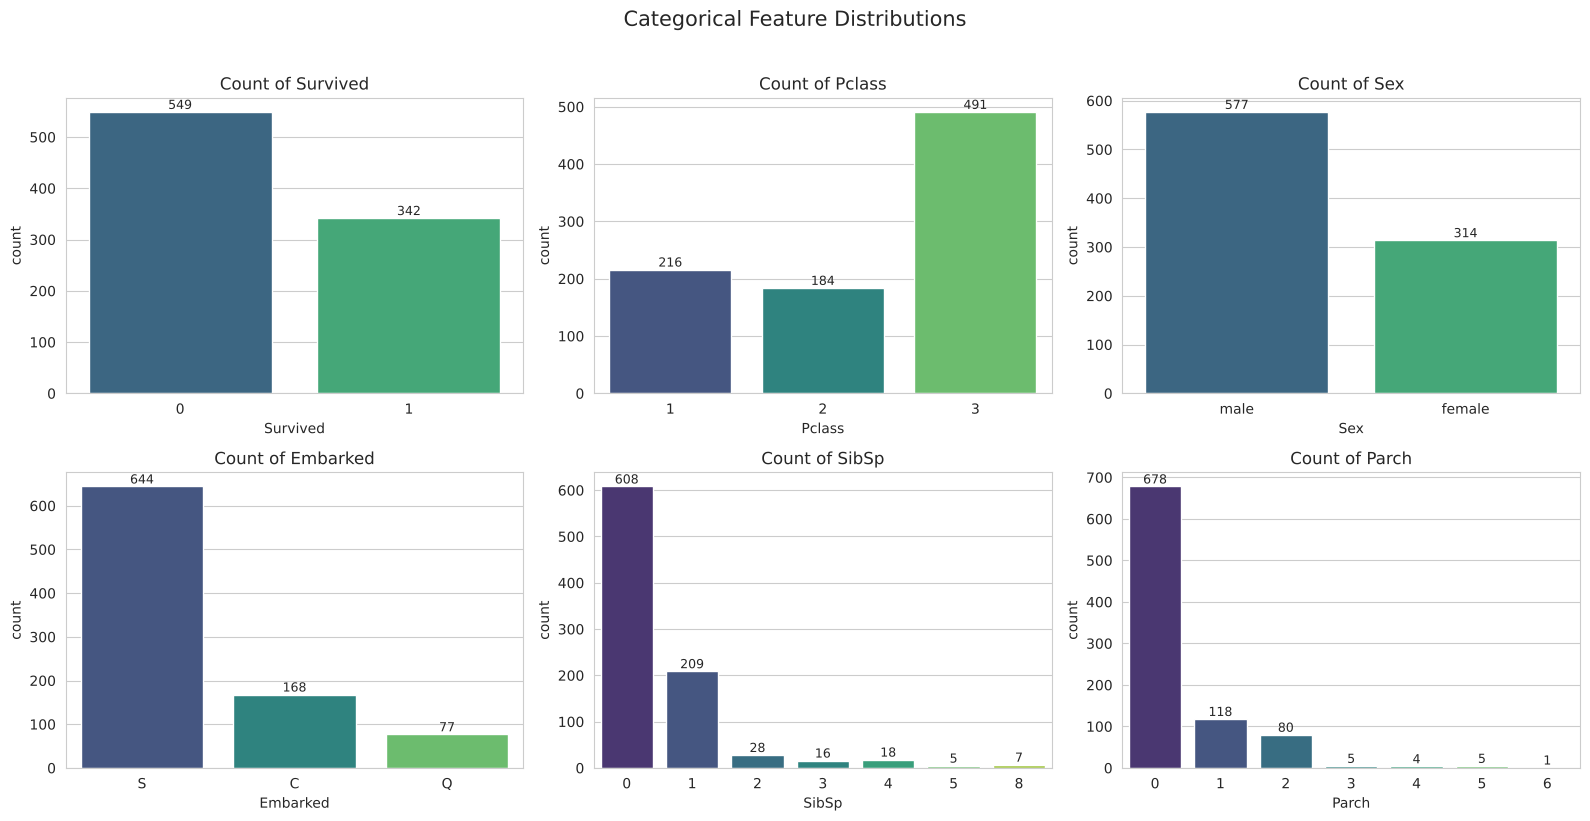

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["Survived", "Pclass", "Sex", "Embarked", "SibSp", "Parch"]):
    order = df[col].value_counts().index if col not in ["Pclass", "SibSp", "Parch"] else sorted(df[col].dropna().unique())
    sns.countplot(data=df, x=col, order=order, palette="viridis", ax=ax)
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Count of {col}")
plt.suptitle("Categorical Feature Distributions", y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig("images/04_categorical_counts.png", dpi=150, bbox_inches="tight")
plt.show()

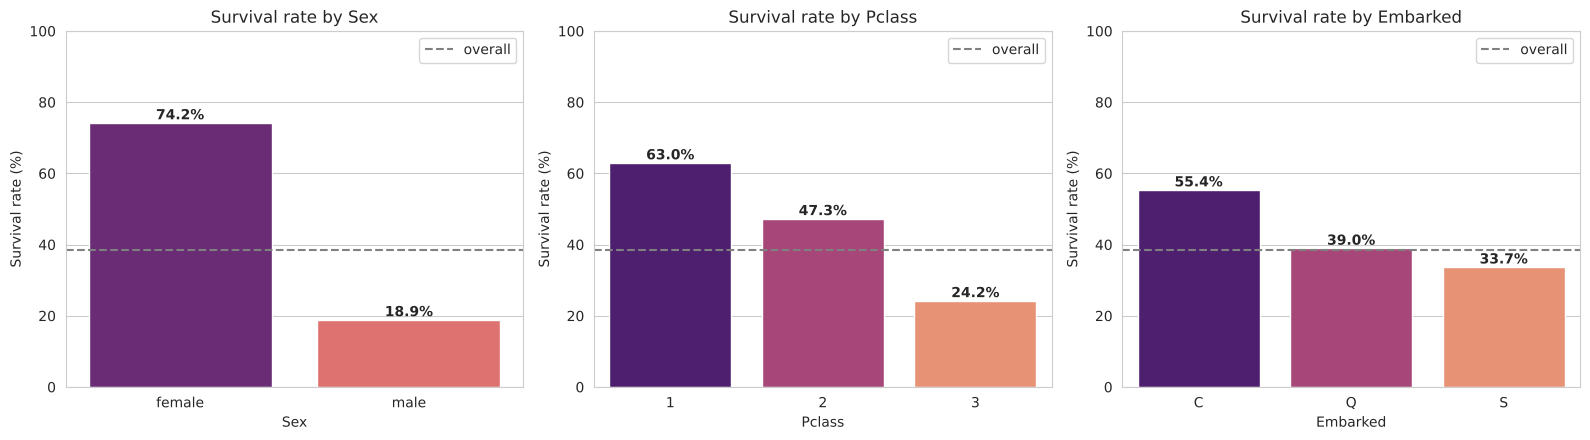

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    rate = df.groupby(col)["Survived"].mean().mul(100)
    sns.barplot(x=rate.index, y=rate.values, palette="magma", ax=ax)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
    ax.axhline(df["Survived"].mean() * 100, color="gray", linestyle="--", label="overall")
    ax.set_ylim(0, 100); ax.set_ylabel("Survival rate (%)"); ax.set_title(f"Survival rate by {col}")
    ax.legend()
plt.tight_layout()
plt.savefig("images/05_survival_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

## 🔗 Step 4: Feature Relationships — Correlation Matrix & Pairplot

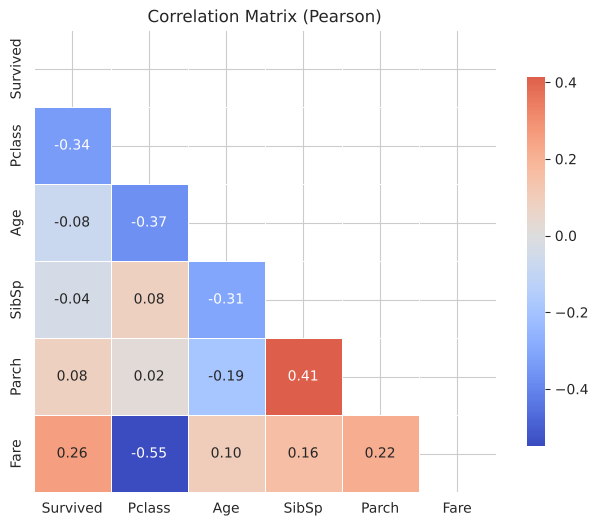

In [14]:
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr = df[corr_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix (Pearson)")
plt.savefig("images/06_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

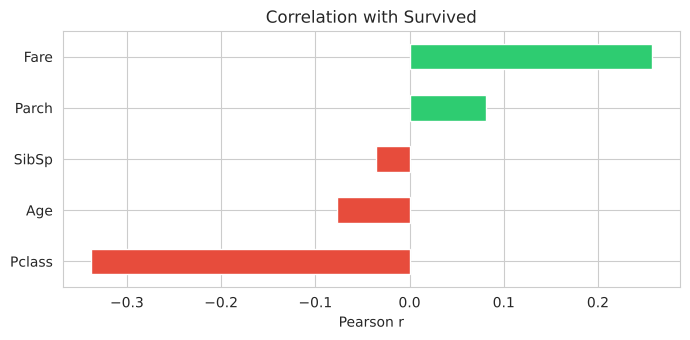

Pclass   -0.338
Age      -0.077
SibSp    -0.035
Parch     0.082
Fare      0.257
Name: Survived, dtype: float64

In [15]:
# Which features correlate most with Survived?
target_corr = corr["Survived"].drop("Survived").sort_values()
plt.figure(figsize=(7, 3.5))
target_corr.plot(kind="barh", color=["#e74c3c" if v < 0 else "#2ecc71" for v in target_corr])
plt.title("Correlation with Survived")
plt.xlabel("Pearson r")
plt.tight_layout()
plt.savefig("images/07_correlation_with_survived.png", dpi=150, bbox_inches="tight")
plt.show()
target_corr.round(3)

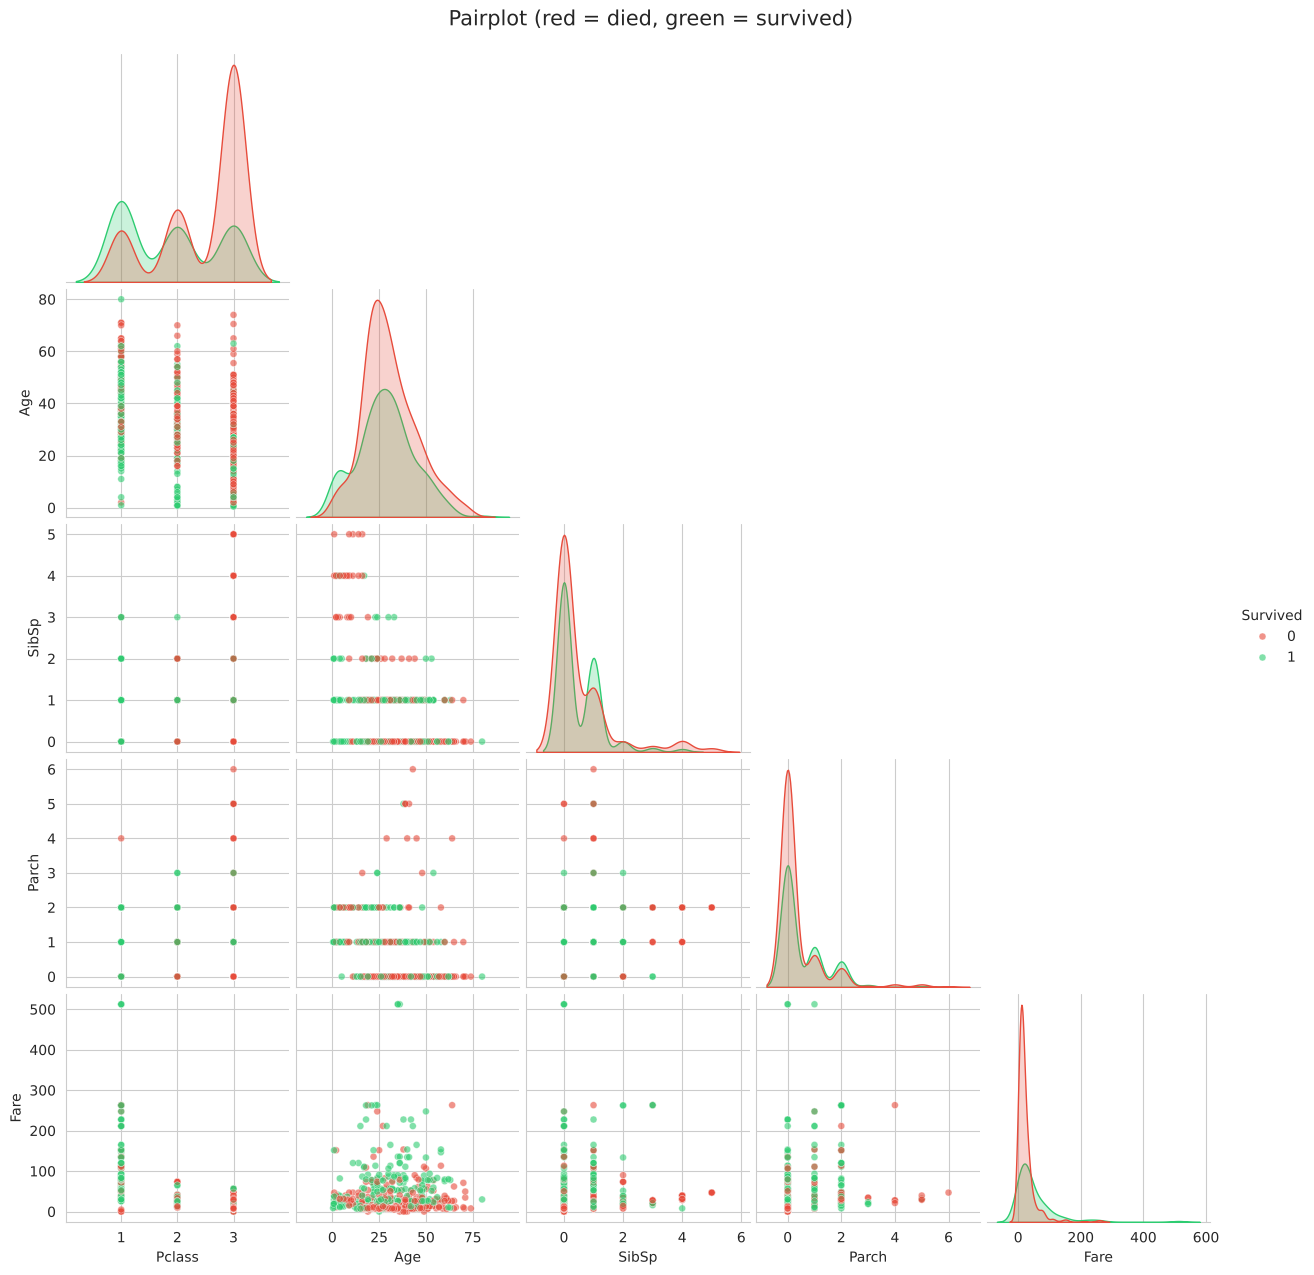

In [16]:
pair_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].dropna()
g = sns.pairplot(pair_df, hue="Survived", palette=SURV_PALETTE, corner=True,
                 diag_kind="kde", plot_kws={"alpha": 0.6, "s": 25})
g.fig.suptitle("Pairplot (red = died, green = survived)", y=1.02, fontsize=15)
plt.savefig("images/08_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

### 🔁 Multicollinearity Check
Correlated predictors can destabilize linear models. A **VIF > 5** is a common warning sign.

In [17]:
from sklearn.linear_model import LinearRegression

X = df[["Pclass", "Age", "SibSp", "Parch", "Fare"]].dropna()
vif = {}
for col in X.columns:
    others = X.drop(columns=col)
    r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
    vif[col] = 1 / (1 - r2)
pd.DataFrame({"VIF": vif}).round(2)

,VIF
Pclass,1.71
Age,1.29
SibSp,1.27
Parch,1.23
Fare,1.58


### 📝 Observations (relationships)
- **Fare** (+0.26) and **Pclass** (−0.34) are the numeric features most linked to survival
- **Pclass ↔ Fare** is the strongest pair (**r ≈ −0.55**): higher class means a higher fare
- **SibSp ↔ Parch** (r ≈ 0.41): large families have both siblings/spouses and parents/children on board
- **Pclass ↔ Age** (r ≈ −0.37): first-class passengers were older
- All VIF values stay low, so multicollinearity is **not a serious problem** in this dataset

## 🔎 Step 5: Patterns, Trends & Anomalies
Interactive **Plotly** charts: hover, zoom and click the legend to explore.

In [18]:
fig = px.histogram(df, x="Age", color=df["Survived"].map({0: "Died", 1: "Survived"}),
                   nbins=30, barmode="overlay", opacity=0.65, marginal="box",
                   color_discrete_map={"Died": "#e74c3c", "Survived": "#2ecc71"},
                   title="Age Distribution by Survival")
fig.update_layout(legend_title_text="Outcome")
fig.write_html("plots_html/age_distribution_by_survival.html", include_plotlyjs="cdn")
fig.show()

In [19]:
rate = (df.groupby(["Pclass", "Sex"])["Survived"].mean().mul(100).round(1).reset_index())
fig = px.bar(rate, x="Pclass", y="Survived", color="Sex", barmode="group", text="Survived",
             color_discrete_map={"female": "#e84393", "male": "#0984e3"},
             labels={"Survived": "Survival rate (%)"},
             title="Survival Rate by Passenger Class and Sex")
fig.update_traces(texttemplate="%{text}%", textposition="outside")
fig.update_layout(yaxis_range=[0, 110], xaxis=dict(dtick=1))
fig.write_html("plots_html/survival_by_class_and_sex.html", include_plotlyjs="cdn")
fig.show()

In [20]:
df["Outcome"] = df["Survived"].map({0: "Died", 1: "Survived"})
fig = px.scatter(df, x="Age", y="Fare", color="Outcome", facet_col="Pclass",
                 color_discrete_map={"Died": "#e74c3c", "Survived": "#2ecc71"},
                 opacity=0.7, hover_data=["Name", "Sex"],
                 title="Age vs Fare by Class (hover for passenger details)")
fig.write_html("plots_html/age_vs_fare_by_class.html", include_plotlyjs="cdn")
fig.show()

In [21]:
fig = px.box(df, x="Pclass", y="Fare", color="Pclass", log_y=True, points="outliers",
             title="Fare by Class (log scale)")
fig.update_layout(showlegend=False, xaxis=dict(dtick=1))
fig.write_html("plots_html/fare_by_class.html", include_plotlyjs="cdn")
fig.show()

In [22]:
fig = px.parallel_categories(df, dimensions=["Pclass", "Sex", "Embarked", "Outcome"],
                             color="Survived", color_continuous_scale=["#e74c3c", "#2ecc71"],
                             title="Passenger Flow: Class → Sex → Port → Outcome")
fig.write_html("plots_html/passenger_flow_parallel_categories.html", include_plotlyjs="cdn")
fig.show()

### 🖼️ Static versions of the interactive charts
GitHub cannot render Plotly's interactive output, so these Matplotlib/Seaborn twins are saved to `images/` for the README.
The interactive originals are saved in `plots_html/`.

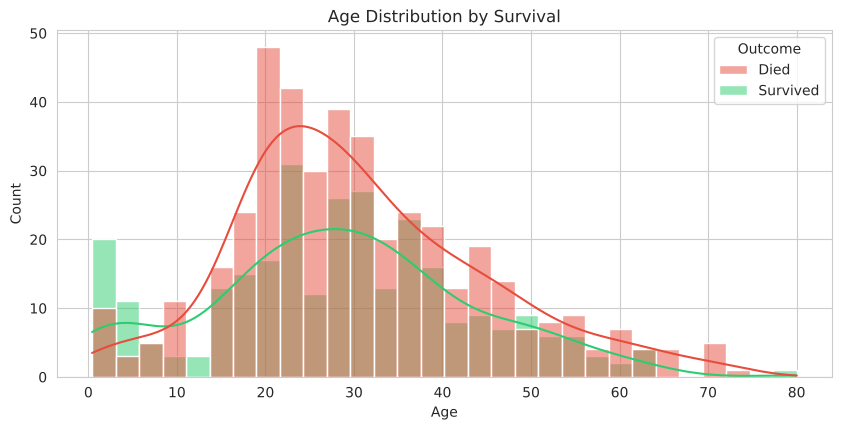

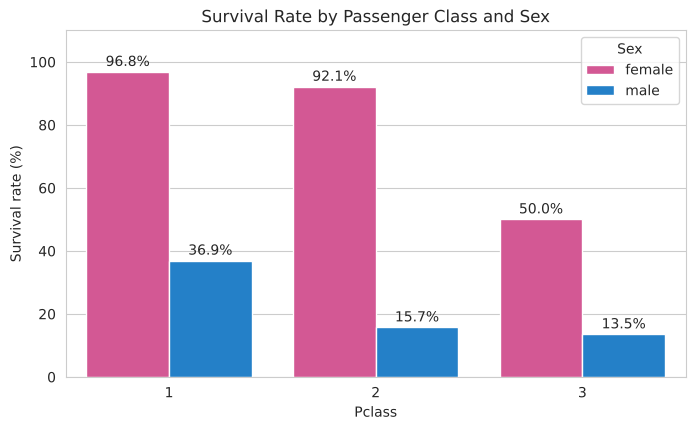

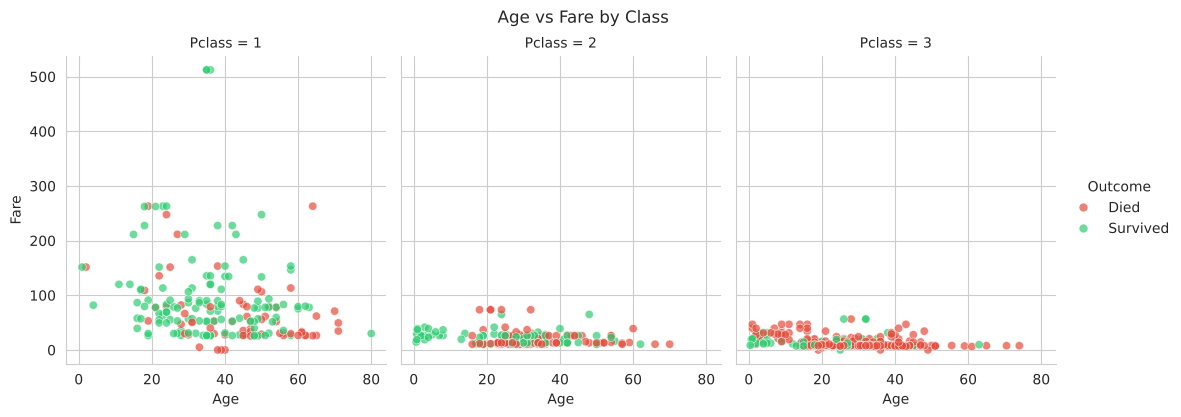

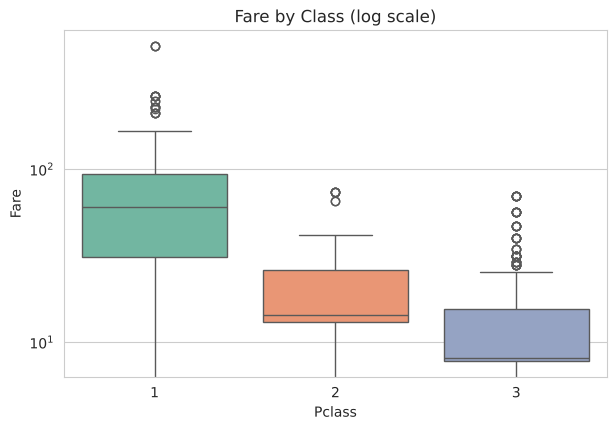

In [23]:

# 10) Age distribution by survival
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(data=df, x="Age", hue="Outcome", bins=30, kde=True, alpha=0.5,
             palette={"Died": "#e74c3c", "Survived": "#2ecc71"}, ax=ax)
ax.set_title("Age Distribution by Survival")
plt.savefig("images/10_age_distribution_by_survival.png", dpi=150, bbox_inches="tight"); plt.show()

# 11) Survival rate by class and sex
rate = df.groupby(["Pclass", "Sex"])["Survived"].mean().mul(100).round(1).reset_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=rate, x="Pclass", y="Survived", hue="Sex",
            palette={"female": "#e84393", "male": "#0984e3"}, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2)
ax.set_ylim(0, 110); ax.set_ylabel("Survival rate (%)")
ax.set_title("Survival Rate by Passenger Class and Sex")
plt.savefig("images/11_survival_by_class_and_sex.png", dpi=150, bbox_inches="tight"); plt.show()

# 12) Age vs Fare by class
g = sns.relplot(data=df, x="Age", y="Fare", hue="Outcome", col="Pclass", kind="scatter", alpha=0.7,
                palette={"Died": "#e74c3c", "Survived": "#2ecc71"}, height=4, aspect=0.9)
g.fig.suptitle("Age vs Fare by Class", y=1.03)
g.savefig("images/12_age_vs_fare_by_class.png", dpi=150, bbox_inches="tight"); plt.show()

# 13) Fare by class (log scale)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="Pclass", y="Fare", palette="Set2", ax=ax)
ax.set_yscale("log"); ax.set_title("Fare by Class (log scale)")
plt.savefig("images/13_fare_by_class.png", dpi=150, bbox_inches="tight"); plt.show()


### 🧪 Engineered features (EDA only: helps uncover hidden patterns)

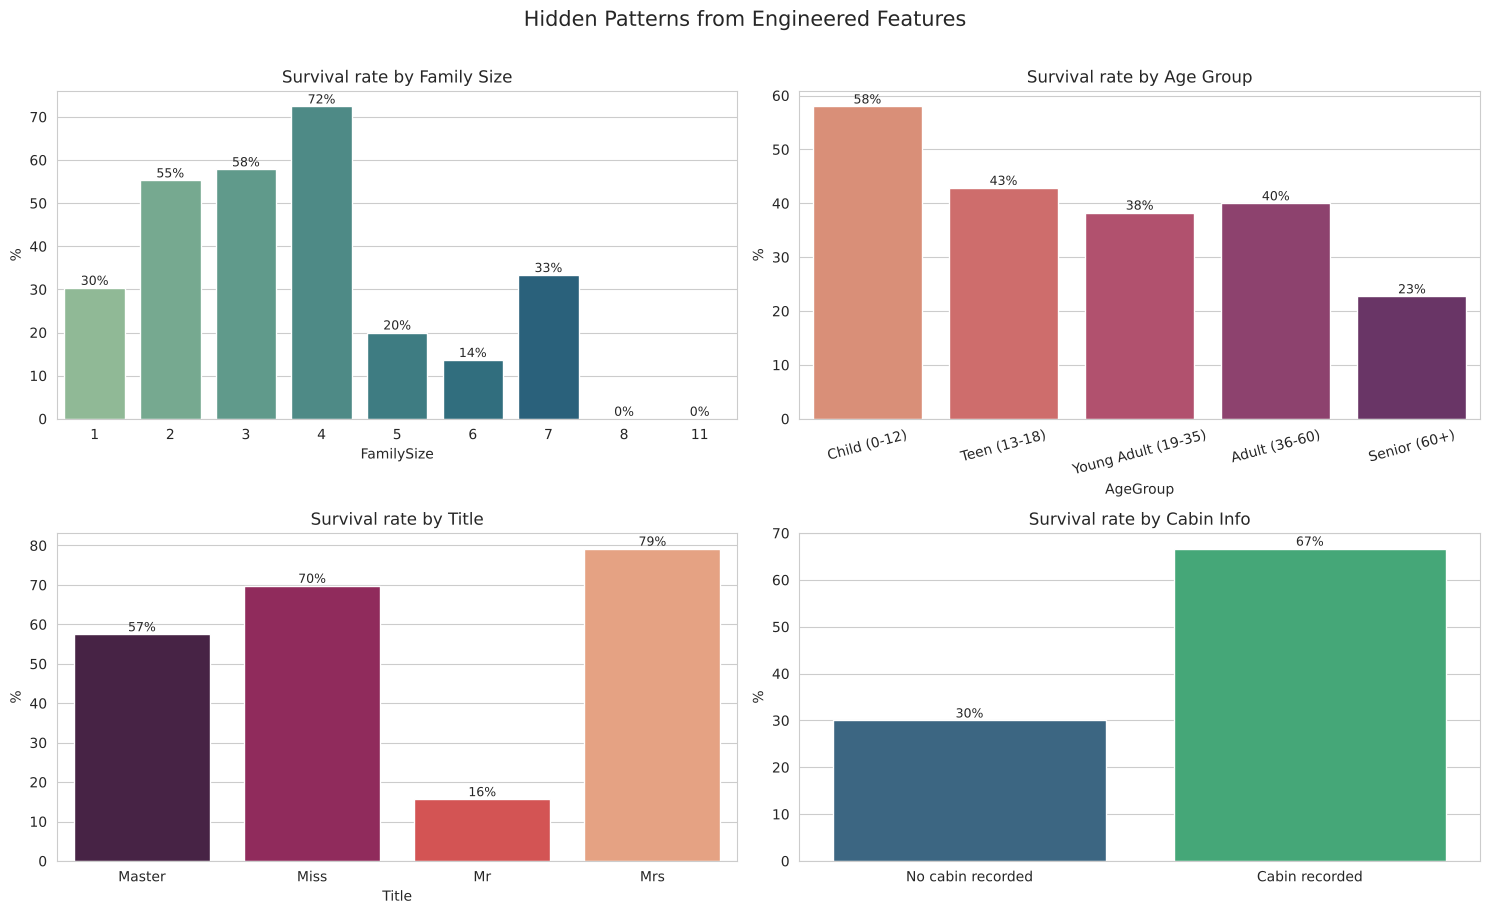

In [24]:
# Family size, age groups, title and cabin deck
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["AgeGroup"] = pd.cut(df["Age"], [0, 12, 18, 35, 60, 100],
                        labels=["Child (0-12)", "Teen (13-18)", "Young Adult (19-35)", "Adult (36-60)", "Senior (60+)"])
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")
df["Deck"] = df["Cabin"].str[0]
df["HasCabin"] = df["Cabin"].notnull().astype(int)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

fs = df.groupby("FamilySize")["Survived"].mean().mul(100)
sns.barplot(x=fs.index, y=fs.values, palette="crest", ax=axes[0, 0])
axes[0, 0].set_title("Survival rate by Family Size"); axes[0, 0].set_ylabel("%")

ag = df.groupby("AgeGroup", observed=True)["Survived"].mean().mul(100)
sns.barplot(x=ag.index, y=ag.values, palette="flare", ax=axes[0, 1])
axes[0, 1].set_title("Survival rate by Age Group"); axes[0, 1].set_ylabel("%")
axes[0, 1].tick_params(axis="x", rotation=15)

tt = df[df["Title"].isin(["Mr", "Miss", "Mrs", "Master"])].groupby("Title")["Survived"].mean().mul(100)
sns.barplot(x=tt.index, y=tt.values, palette="rocket", ax=axes[1, 0])
axes[1, 0].set_title("Survival rate by Title"); axes[1, 0].set_ylabel("%")

hc = df.groupby("HasCabin")["Survived"].mean().mul(100)
sns.barplot(x=["No cabin recorded", "Cabin recorded"], y=hc.values, palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("Survival rate by Cabin Info"); axes[1, 1].set_ylabel("%")

for ax in axes.ravel():
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.suptitle("Hidden Patterns from Engineered Features", y=1.01, fontsize=15)
plt.tight_layout()
plt.savefig("images/09_engineered_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# Fare quartiles vs survival
df["FareQuartile"] = pd.qcut(df["Fare"], 4, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4 (most expensive)"])
fq = df.groupby("FareQuartile", observed=True)["Survived"].agg(["mean", "count"])
fq["mean"] = (fq["mean"] * 100).round(1)
fq.rename(columns={"mean": "Survival %", "count": "Passengers"})

,Survival %,Passengers
FareQuartile,,
Q1 (cheapest),19.7,223
Q2,30.4,224
Q3,45.5,222
Q4 (most expensive),58.1,222


### 🚨 Anomalies & Data Quality Issues

In [26]:
print("1) Missing values by class (is Age missing at random?)")
print(df.assign(AgeMissing=df["Age"].isnull()).groupby("Pclass")["AgeMissing"].mean().mul(100).round(1).astype(str) + " %")

print("\n2) Passengers with Fare = 0:", (df["Fare"] == 0).sum())
display(df[df["Fare"] == 0][["Name", "Pclass", "Age", "Embarked", "Survived"]].head(6))

print("\n3) Highest fares (identical 512.33 values):")
display(df.nlargest(4, "Fare")[["Name", "Pclass", "Fare", "Survived"]])

print("\n4) Youngest passengers (infants):")
display(df.nsmallest(4, "Age")[["Name", "Age", "Pclass", "Survived"]])

print("\n5) Largest families (SibSp >= 5): ", len(df[df["SibSp"] >= 5]), "passengers, survivors:", int(df[df["SibSp"] >= 5]["Survived"].sum()))

1) Missing values by class (is Age missing at random?)
Pclass
1    13.9 %
2     6.0 %
3    27.7 %
Name: AgeMissing, dtype: str

2) Passengers with Fare = 0: 15


,Name,Pclass,Age,Embarked,Survived
179,"Leonard, Mr. Lionel",3,36.0,S,0
263,"Harrison, Mr. William",1,40.0,S,0
271,"Tornquist, Mr. William Henry",3,25.0,S,1
277,"Parkes, Mr. Francis ""Frank""",2,NaN,S,0
302,"Johnson, Mr. William Cahoone Jr",3,19.0,S,0
413,"Cunningham, Mr. Alfred Fleming",2,NaN,S,0



3) Highest fares (identical 512.33 values):


,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0



4) Youngest passengers (infants):


,Name,Age,Pclass,Survived
803,"Thomas, Master. Assad Alexander",0.42,3,1
755,"Hamalainen, Master. Viljo",0.67,2,1
469,"Baclini, Miss. Helene Barbara",0.75,3,1
644,"Baclini, Miss. Eugenie",0.75,3,1



5) Largest families (SibSp >= 5):  12 passengers, survivors: 0


## 🧠 Step 6: Feature-Level Inferences (from the visuals)

| Feature | What the data shows | Inference |
|---|---|---|
| **Sex** | Women survived at **74.2%** vs men at **18.9%** | Strongest single predictor ("women and children first") |
| **Pclass** | 1st: **63.0%**, 2nd: **47.3%**, 3rd: **24.2%** | Social class strongly affected survival |
| **Sex × Pclass** | 1st-class women **96.8%** survived; 3rd-class men only **13.5%** | Sex and class interact: both matter together |
| **Age** | Children (0-12) survived at **58%**, seniors (60+) at **22.7%** | Young children were prioritised; the elderly fared worst |
| **Fare** | Survival rises from **19.7%** (cheapest quartile) to **58.1%** (priciest) | Fare mostly proxies class; heavily skewed, so use a log transform |
| **Embarked** | Cherbourg **55.4%**, Queenstown **39.0%**, Southampton **33.7%** | Cherbourg had more first-class passengers (51%), not a direct port effect |
| **Family size** | Alone **30.4%**; families of 2-4 **55-72%**; 5+ **0-33%** | Small families helped; very large families fared badly |
| **Title** | Mrs **79.2%**, Miss **69.8%**, Master **57.5%**, Mr **15.7%** | Title captures sex + age + marital status in one feature |
| **Cabin** | With cabin **66.7%** vs without **30.0%** | A recorded cabin signals wealth; `HasCabin` is a useful feature |
| **Age (missing)** | 177 missing, more common in 3rd class | Not missing completely at random: impute by group, not globally |

### ⚠️ Anomalies noticed
- **15 passengers paid Fare = 0** (likely crew / staff or data gaps)
- **Three passengers share the maximum fare of 512.33**: extreme but valid first-class tickets
- **Cabin is 77% missing**, mostly third class, so missingness itself carries information
- **Fare skewness ≈ 4.8** and kurtosis ≈ 33: needs a log or power transform for ML

### 🤖 Modelling recommendations
1. Keep `Sex`, `Pclass`, `Age`, `Fare` (log), `FamilySize`, `HasCabin` / `Title` as strong features
2. Impute `Age` using group medians (`Pclass` + `Sex`), as done in Task 1
3. Do not drop the "outliers" in `SibSp` / `Parch`: they are genuine
4. Correlations are mild and VIFs low, so linear models won't suffer from multicollinearity

## ✅ Conclusion
EDA of the Titanic dataset showed that **survival was driven mainly by sex, passenger class, age and family size**.
Women, first-class passengers, children and small families survived far more often, while men, third-class passengers
and people travelling in very large groups fared worst. `Fare` is highly skewed, `Cabin` is mostly missing, and
`Age` is missing non-randomly. These insights directly guide feature engineering and preprocessing for a survival model.

## 🎤 Interview Questions — Short Answers
1. **What is the purpose of EDA?** To understand the data before modelling: its structure, distributions, missing values, outliers, relationships and anomalies, so you can make good preprocessing and modelling decisions.
2. **How do boxplots help?** They summarise the median, quartiles, spread and outliers in one picture, and make it easy to compare distributions across groups.
3. **What is correlation and why is it useful?** A measure (−1 to +1) of how strongly two variables move together. It helps find predictive features and redundant ones. Correlation does not imply causation.
4. **How do you detect skewness?** Histogram/KDE shape, mean vs median gap, and `df.skew()` (|skew| > 1 is strongly skewed). Fix with log, square-root or Box-Cox transforms.
5. **What is multicollinearity?** When predictors are highly correlated with each other, making linear-model coefficients unstable. Detect with a correlation matrix or VIF (> 5-10); fix by dropping/combining features or using regularization / PCA.
6. **What tools do you use for EDA?** Pandas, NumPy, Matplotlib, Seaborn, Plotly, plus profiling libraries such as ydata-profiling or Sweetviz.
7. **A time EDA helped find a problem?** On the Titanic data: EDA showed `Age` was missing far more often in third class (27.7% vs 6.0% in second) and `Fare` was heavily skewed, so I chose group-wise imputation and a log transform instead of one global fix.
8. **Role of visualization in ML?** It reveals patterns, outliers and data-quality issues, guides feature engineering, helps pick models, and is used to evaluate and explain results (confusion matrix, ROC curve, feature importance).